In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from seaborn import heatmap
import matplotlib.pyplot as plt
from itertools import combinations
import statsmodels.api as sm

In [2]:
data = pd.read_csv('stock_dsf.csv')
data = data.pivot(index='dlycaldt', columns='permno', values='dlyretx')
data = data.dropna(axis=1)
data.index = pd.to_datetime(data.index,format = '%Y-%m-%d')
#r7_return = pd.read_csv("r7_return.csv")
sp500_return = pd.read_csv("sp500 return.csv")
#data = data.fillna(method='ffill')
#data = data.fillna(method='bfill')
data

permno,10026,10028,10032,10044,10104,10107,10138,10145,10158,10200,...,93368,93371,93372,93374,93397,93426,93427,93429,93434,93436
dlycaldt,,,,,,,,,,,,,,,,,,,,,
2014-01-02,-0.016255,-0.035874,-0.011781,-0.005168,-0.010978,-0.006683,-0.014444,-0.011492,0.012422,-0.074047,...,-0.002101,0.096774,-0.013080,-0.013475,-0.003385,0.026864,-0.042802,-0.018861,0.024460,-0.002187
2014-01-03,0.000918,0.032558,0.000234,0.003463,-0.005814,-0.006728,0.008963,0.002214,0.016360,0.011085,...,-0.001135,0.096985,0.004217,-0.009705,-0.001132,0.017005,-0.006606,0.013339,-0.025281,-0.003598
2014-01-06,-0.016393,0.015766,-0.011685,0.014668,-0.003987,-0.021133,-0.001561,-0.000994,-0.020121,-0.000783,...,-0.000238,-0.021382,-0.011398,-0.003267,-0.003022,0.007717,-0.028133,-0.014131,0.001441,-0.017117
2014-01-07,0.013170,-0.028825,0.022464,0.004252,0.010141,0.007750,0.008417,0.004092,0.021561,0.007837,...,0.003731,0.027397,0.010316,0.003277,0.004168,0.008296,-0.006316,-0.004712,0.028777,0.016054
2014-01-08,-0.012769,0.041096,0.006938,0.005080,-0.003435,-0.017852,0.000596,-0.003965,0.017085,-0.006998,...,0.004502,0.066600,-0.007808,-0.002178,-0.001887,0.000000,-0.009004,-0.013218,-0.057343,0.012855
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.002864,0.025947,0.011107,-0.020576,0.013421,0.009374,0.008615,0.007749,0.029759,0.008926,...,0.004276,-0.010689,-0.003387,0.016480,-0.069898,0.007427,0.001585,0.006784,-0.005217,0.073572
2024-12-26,0.001841,-0.008886,0.003227,0.025210,0.001575,-0.002777,0.004356,0.012931,-0.002550,-0.007962,...,0.002293,0.020408,0.005098,-0.001259,-0.041283,0.035559,0.013153,0.011008,0.236014,-0.017630
2024-12-27,-0.010516,-0.013793,-0.023879,-0.016393,-0.015843,-0.017302,-0.016244,-0.010135,-0.012356,-0.001646,...,-0.002614,-0.034118,-0.014370,-0.014342,0.020067,-0.022613,-0.020879,0.003460,0.304102,-0.049479


In [71]:
data_month = data + 1
data_month = data_month.cumprod()
data_month = data_month.resample('MS').first().pct_change().dropna(axis=0)
data_month[14593]

permno,10026,10028,10032,10044,10104,10107,10138,10145,10158,10200,...,93368,93371,93372,93374,93397,93426,93427,93429,93434,93436
dlycaldt,,,,,,,,,,,,,,,,,,,,,
2014-02-01,-0.021572,-0.032557,-0.114540,0.008656,-0.052854,-0.018299,-0.083456,-0.017384,-0.036811,0.158351,...,-0.006874,0.647060,-0.137349,-0.090582,-0.214717,-0.064096,-0.064026,-0.036288,-0.134832,0.179946
2014-03-01,0.095814,0.168219,0.083159,0.005152,0.074500,0.035633,0.054976,0.054536,0.060507,0.026657,...,-0.009207,0.294645,0.131285,0.033199,0.014418,0.185185,0.060803,0.127620,0.067048,0.414715
2014-04-01,0.033286,-0.082266,-0.003656,0.002561,0.077381,0.096348,0.042088,-0.003529,-0.237238,-0.097869,...,0.057637,-0.179312,0.079629,0.035959,0.073899,0.039505,0.048617,0.016608,0.136465,-0.134059
2014-05-01,-0.056448,0.219732,0.025685,-0.003408,-0.012532,-0.034282,-0.021995,-0.010938,-0.166666,0.157193,...,-0.041302,-0.247900,-0.026871,-0.017356,-0.004411,-0.079411,0.033187,-0.050783,-0.001339,-0.042587
2014-06-01,0.018661,-0.261067,-0.017649,-0.009314,0.024409,0.019748,0.004548,0.012684,0.012597,0.221938,...,-0.027523,-0.184357,0.025855,0.038708,0.015507,-0.013557,-0.105339,-0.060047,-0.112602,-0.014588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-08-01,0.014975,0.052176,0.211972,-0.208531,-0.038995,-0.086747,-0.015986,-0.030195,0.117309,0.343415,...,0.074104,0.042056,0.283917,0.128888,0.049630,0.119693,-0.114987,0.080445,0.149620,0.033355
2024-09-01,0.019295,0.051651,-0.017988,0.077844,0.014474,-0.018390,-0.067392,0.001369,0.016179,-0.144143,...,0.066143,0.309415,-0.038138,0.057583,0.132023,-0.203046,0.027304,0.145842,-0.358333,-0.028865
2024-10-01,0.013068,0.027506,0.101645,0.083334,0.198280,0.027478,0.025175,0.005905,0.263888,0.027857,...,0.054037,0.386986,0.005096,0.034050,0.088089,-0.063319,0.040392,-0.013626,-0.180676,0.225168


In [ ]:
#AR1

In [83]:
def garch_loglik_0fac(params, stock):
    eps = 0
    sigma = np.std(stock)
    log_lik = 0
    
    for i in range(1, len(stock)):
        y = stock[i]
        mu = params[0] + params[1] * stock[i-1]
        #mu = params[0]
        # sigma = (np.exp(params[2]+params[3]*np.abs(eps)+params[4]*eps+params[5]*np.log(sigma**2)))**0.5
        # if (params[3] + params[4]*eps**2 + params[5]*sigma**2) < 0:
        #     return np.inf
        sigma = (params[2]+ params[3]*eps**2 + params[4]*sigma**2)**0.5
        eps = (y - mu)
        log_lik += -0.5 * (np.log(sigma**2) + ((y-mu)/sigma)**2)

    return -log_lik

def get_standard_resid_0fac(params, stock):
    eps = [0]
    sigma = np.std(stock)
    for i in range(1, len(stock)):
        y = stock[i]
        mu = params[0] + params[1] * stock[i-1]
        sigma = (params[2] + params[3]*eps[i-1]**2 + params[4]*sigma**2)**0.5
        eps.append((y - mu)/sigma)
    
    return eps

def get_sigma_0fac(params, stock):
    eps = 0
    sigma = [np.std(stock)]
    for i in range(1, len(stock)):
        y = stock[i]
        mu = params[0] + params[1] * stock[i-1]
        sigma.append((params[2] + params[3]*eps**2 + params[4]*sigma[i-1]**2)**0.5)
        eps = (y - mu) / sigma[i]
        
    return sigma

def dcc_loglik(params, resid):
    # residual is T x k matrix, k is number of asset
    T = resid.shape[0]
    Q_bar = np.mean([np.outer(resid[t, :], resid[t, :]) for t in range(T)], axis=0)
    Q = Q_bar.copy()
    log_lik = 0
    for t in range(1, T):
        resid_tm1 = resid[t-1, :].reshape(-1, 1)
        eps_sq = np.dot(resid_tm1, resid_tm1.T)
        Q = (1-params[0]-params[1]) * Q_bar + params[0] * eps_sq + params[1] * Q
        Q_std = np.sqrt(np.diag(Q)).reshape(-1, 1)
        R = Q / np.outer(Q_std, Q_std)
        
        R_det = np.linalg.det(R)
        R_inv = np.linalg.inv(R)
        if R_det <= 0 or np.abs(R_det) < 0.001:
            return log_lik + 1e9
            
        log_lik += -np.log(R_det) - np.dot(np.dot(resid_tm1.T, R_inv), resid_tm1)
        
    
    return -log_lik


In [97]:
ticker_list = ['AAPL', 'MSFT', 'GOOG', 'NVDA', 'TSLA', 'META', 'AMZN', 'AVGO',
       'ACN', 'ADBE', 'AMAT', 'AMD', 'CRM', 'CSCO', 'IBM', 'INTC', 'INTU',
       'MU', 'ORCL', 'QCOM', 'TXN', 'ABBV', 'ABT', 'AMGN', 'BIIB', 'BMY',
       'CVS', 'GILD', 'ISRG', 'JNJ', 'LLY', 'MDT', 'MRK', 'PFE', 'TMO', 'UNH',
       'WBA', 'AIG', 'AXP', 'BAC', 'BRK', 'C', 'GS', 'JPM', 'MA', 'PYPL',
       'SCHW', 'USB', 'V', 'WFC', 'BKNG', 'EBAY', 'HD', 'LOW', 'MCD', 'SBUX',
       'COST', 'KO', 'MO', 'PEP', 'PG', 'PM', 'WMT', 'BA', 'CAT', 'DE', 'GE',
       'HON', 'LMT', 'MMM', 'RTX', 'UNP', 'UPS', 'CHTR', 'CMCSA', 'DIS',
       'NFLX', 'T', 'VZ', 'COP', 'CVX', 'KMI', 'OXY', 'SLB', 'XOM']
permno_list = pd.read_csv('new_ticker_list.csv')
permno_map = dict(zip(permno_list['ticker'], permno_list['permno']))
mapped_permnos = [permno_map.get(ticker, 15488) for ticker in ticker_list]

In [84]:
init_params_0fac = [0.01, 0.01, 0, 0.1, 0.9]
params_0fac = {}
resid_0fac = {}
sigma_0fac = {}
for ticker in data.columns:
    print(ticker)
    stock = np.array(data[ticker])
    # r7 = np.array(r7_return["return"])
    # r493 = np.array(sp500_return["sprtrn"] - r7)
    # r500 = np.array(sp500_return["sprtrn"])
    res = minimize(garch_loglik_0fac, init_params_0fac, args=(stock), method='Nelder-Mead', tol=1e-4, 
                bounds=[(None, None), (None, None), (None, None), (0.001, 0.999), (0.001, 0.999)], options={"maxiter":1000, "disp":True})
    params_0fac[ticker] = res.x
    resid_0fac[ticker] = get_standard_resid_0fac(res.x, stock)
    sigma_0fac[ticker] = get_sigma_0fac(res.x,stock)

10026


/var/folders/21/vkszmnmn6w9c_0f5lply6l400000gn/T/ipykernel_58509/2780765505.py:13: RuntimeWarning: invalid value encountered in scalar power
  sigma = (params[2]+ params[3]*eps**2 + params[4]*sigma**2)**0.5


Optimization terminated successfully.
         Current function value: -10213.504455
         Iterations: 292
         Function evaluations: 480
10028
Optimization terminated successfully.
         Current function value: -7429.608118
         Iterations: 230
         Function evaluations: 372
10032
Optimization terminated successfully.
         Current function value: -9744.186858
         Iterations: 421
         Function evaluations: 666
10044
Optimization terminated successfully.
         Current function value: -9478.626795
         Iterations: 294
         Function evaluations: 472
10104
Optimization terminated successfully.
         Current function value: -10100.612892
         Iterations: 256
         Function evaluations: 409
10107
Optimization terminated successfully.
         Current function value: -10225.244624
         Iterations: 324
         Function evaluations: 528
10138
Optimization terminated successfully.
         Current function value: -10111.324494
         Ite

In [85]:
pd.DataFrame(params_0fac).transpose().to_csv("params_0fac_ar1.csv")
df = pd.DataFrame.from_dict(resid_0fac, orient="index").T
df.to_csv("resid_0fac_ar1.csv")
df = pd.DataFrame.from_dict(sigma_0fac, orient="index").T
df.to_csv("sigma_0fac_ar1.csv")

In [ ]:
import itertools
init_params_dcc = [0.1, 0.9]
params_dcc = {}
for ticker_1, ticker_2 in combinations(ticker_list, 2):
    # if ticker_1 == "SPX" or ticker_2 == "SPX":
    #     continue
    if len(resid_0fac[ticker_1])>len(resid_0fac[ticker_2]):
        resid_0fac_ticker_1 = resid_0fac[ticker_1][len(resid_0fac[ticker_1])-len(resid_0fac[ticker_2]):]
        resid_0fac_ticker_2 = resid_0fac[ticker_2] 
    if len(resid_0fac[ticker_2])>len(resid_0fac[ticker_1]):
        resid_0fac_ticker_2 = resid_0fac[ticker_2][len(resid_0fac[ticker_2])-len(resid_0fac[ticker_1]):]
        resid_0fac_ticker_1 = resid_0fac[ticker_1]
    if len(resid_0fac[ticker_2])==len(resid_0fac[ticker_1]):
        resid_0fac_ticker_1 = resid_0fac[ticker_1]
        resid_0fac_ticker_2 = resid_0fac[ticker_2]    
    resids = np.vstack((resid_0fac_ticker_1, resid_0fac_ticker_2)).T
    res = minimize(dcc_loglik, init_params_dcc, args=(resids), tol=1e-4,
                bounds=[(0, 0.999), (0, 0.999)], constraints = {'type': 'ineq', 'fun': lambda x:  -x[0] - x[1] + 1}, options={"maxiter":10000, "disp":True})
    
    params_dcc[ticker_1, ticker_2] = res.x
    params_dcc[ticker_2, ticker_1] = res.x

Optimization terminated successfully    (Exit mode 0)
            Current function value: -2927.6840056919837
            Iterations: 12
            Function evaluations: 31
            Gradient evaluations: 8
Optimization terminated successfully    (Exit mode 0)
            Current function value: -2490.7019996525205
            Iterations: 11
            Function evaluations: 27
            Gradient evaluations: 7
Optimization terminated successfully    (Exit mode 0)
            Current function value: -2247.6101230667045
            Iterations: 11
            Function evaluations: 27
            Gradient evaluations: 7
Optimization terminated successfully    (Exit mode 0)
            Current function value: -1659.8509119113255
            Iterations: 11
            Function evaluations: 27
            Gradient evaluations: 7
Optimization terminated successfully    (Exit mode 0)
            Current function value: -2524.713406495726
            Iterations: 13
            Function eva

/var/folders/ch/n12xxxw10_d88m454rvqbvq40000gn/T/ipykernel_4010/1942654869.py:40: RuntimeWarning: invalid value encountered in sqrt
  Q_std = np.sqrt(np.diag(Q)).reshape(-1, 1)
/opt/anaconda3/lib/python3.12/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


Optimization terminated successfully    (Exit mode 0)
            Current function value: -2239.107660371878
            Iterations: 16
            Function evaluations: 49
            Gradient evaluations: 12
Optimization terminated successfully    (Exit mode 0)
            Current function value: -1581.864788494951
            Iterations: 10
            Function evaluations: 23
            Gradient evaluations: 6
Optimization terminated successfully    (Exit mode 0)
            Current function value: -1657.3345287459179
            Iterations: 11
            Function evaluations: 27
            Gradient evaluations: 7
Optimization terminated successfully    (Exit mode 0)
            Current function value: -2058.769507228525
            Iterations: 12
            Function evaluations: 31
            Gradient evaluations: 8
Optimization terminated successfully    (Exit mode 0)
            Current function value: -2032.6102300946332
            Iterations: 13
            Function eval

In [81]:
init_params_0fac_m = [0.01, 0.01, 0, 0.1, 0.9]
params_0fac_m = {}
resid_0fac_m = {}
sigma_0fac_m = {}
for ticker in data_month.columns:
    print(ticker)
    stock = np.array(data_month[ticker])
    # r7 = np.array(r7_return["return"])
    # r493 = np.array(sp500_return["sprtrn"] - r7)
    # r500 = np.array(sp500_return["sprtrn"])
    res = minimize(garch_loglik_0fac, init_params_0fac_m, args=(stock), method='Nelder-Mead', tol=1e-4, 
                bounds=[(None, None), (None, None), (None, None), (0.001, 0.999), (0.001, 0.999)], options={"maxiter":1000, "disp":True})
    params_0fac_m[ticker] = res.x
    resid_0fac_m[ticker] = get_standard_resid_0fac(res.x, stock)
    sigma_0fac_m[ticker] = get_sigma_0fac(res.x,stock)

10026
Optimization terminated successfully.
         Current function value: -288.034451
         Iterations: 457
         Function evaluations: 721
10028
Optimization terminated successfully.
         Current function value: -154.959303
         Iterations: 196
         Function evaluations: 317
10032
Optimization terminated successfully.
         Current function value: -270.448042
         Iterations: 235
         Function evaluations: 375
10044
Optimization terminated successfully.
         Current function value: -235.312001
         Iterations: 231
         Function evaluations: 378
10104


/var/folders/21/vkszmnmn6w9c_0f5lply6l400000gn/T/ipykernel_58509/2780765505.py:13: RuntimeWarning: invalid value encountered in scalar power
  sigma = (params[2]+ params[3]*eps**2 + params[4]*sigma**2)**0.5


Optimization terminated successfully.
         Current function value: -294.618998
         Iterations: 260
         Function evaluations: 417
10107
Optimization terminated successfully.
         Current function value: -297.228680
         Iterations: 240
         Function evaluations: 395
10138
Optimization terminated successfully.
         Current function value: -277.013797
         Iterations: 247
         Function evaluations: 396
10145
Optimization terminated successfully.
         Current function value: -315.259964
         Iterations: 232
         Function evaluations: 377
10158
Optimization terminated successfully.
         Current function value: -175.490235
         Iterations: 292
         Function evaluations: 465
10200
Optimization terminated successfully.
         Current function value: -207.928614
         Iterations: 239
         Function evaluations: 387
10220
Optimization terminated successfully.
         Current function value: -275.039039
         Iterations: 29

/var/folders/21/vkszmnmn6w9c_0f5lply6l400000gn/T/ipykernel_58509/3354431757.py:11: RuntimeWarning: Maximum number of iterations has been exceeded.
  res = minimize(garch_loglik_0fac, init_params_0fac_m, args=(stock), method='Nelder-Mead', tol=1e-4,


14030
Optimization terminated successfully.
         Current function value: -256.976450
         Iterations: 247
         Function evaluations: 399
14033
Optimization terminated successfully.
         Current function value: -147.159051
         Iterations: 245
         Function evaluations: 397
14044
Optimization terminated successfully.
         Current function value: -172.765015
         Iterations: 265
         Function evaluations: 421
14045
Optimization terminated successfully.
         Current function value: -197.429601
         Iterations: 379
         Function evaluations: 600
14056
Optimization terminated successfully.
         Current function value: -109.423235
         Iterations: 362
         Function evaluations: 581
14060
Optimization terminated successfully.
         Current function value: -105.461728
         Iterations: 251
         Function evaluations: 406
14072
Optimization terminated successfully.
         Current function value: -137.143106
         Iteratio

In [82]:
pd.DataFrame(params_0fac_m).transpose().to_csv("params_0fac_ar1_m.csv")
df = pd.DataFrame.from_dict(resid_0fac_m, orient="index").T
df.to_csv("resid_0fac_ar1_m.csv")
df = pd.DataFrame.from_dict(sigma_0fac_m, orient="index").T
df.to_csv("sigma_0fac_ar1_m.csv")

In [28]:
resid = pd.read_csv('resid_0fac_ar1.csv',index_col=0)
resid.set_index(data.index,inplace=True)

In [36]:
mag7_permnos = [10107, 13407, 14593, 84788, 86580, 90319]
mag7_tickers = ['MSFT','META','AAPL','AMZN','NVDA','GOOG','TSLA']
#93436

In [39]:
data_big = data[permno_list]
corrdict={}
for i in range(2014,2025):
    corrdict[i] = data_big[data_big.index.year == i].corr().values.mean()
corrdict

{2014: np.float64(0.2735414839460633),
 2015: np.float64(0.3570633698041757),
 2016: np.float64(0.2719179629985385),
 2017: np.float64(0.12395626937709942),
 2018: np.float64(0.31071145283083923),
 2019: np.float64(0.240613647015915),
 2020: np.float64(0.49468241202422186),
 2021: np.float64(0.22152960125514226),
 2022: np.float64(0.37531073841084006),
 2023: np.float64(0.22137038715268256),
 2024: np.float64(0.16161594176146313)}

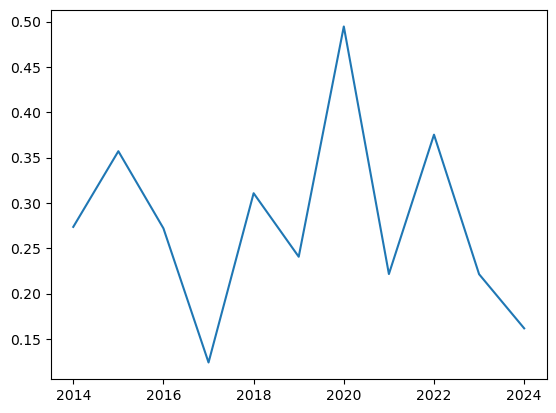

In [40]:
plt.plot(corrdict.keys(),corrdict.values())

In [25]:
resid_big = resid[permno_list.astype('str')]
residcorrdict={}
for i in range(2014,2025):
    residcorrdict[i] = resid_big[resid_big.index.year == i].corr().values.mean()
residcorrdict

{2014: np.float64(0.24229446142256977),
 2015: np.float64(0.328161593984081),
 2016: np.float64(0.25195667287875567),
 2017: np.float64(0.12273829239628235),
 2018: np.float64(0.2735696139588336),
 2019: np.float64(0.2190382619145607),
 2020: np.float64(0.41305044534095436),
 2021: np.float64(0.2099661822622617),
 2022: np.float64(0.3649843767178795),
 2023: np.float64(0.21647686210834002),
 2024: np.float64(0.15208332076267475)}

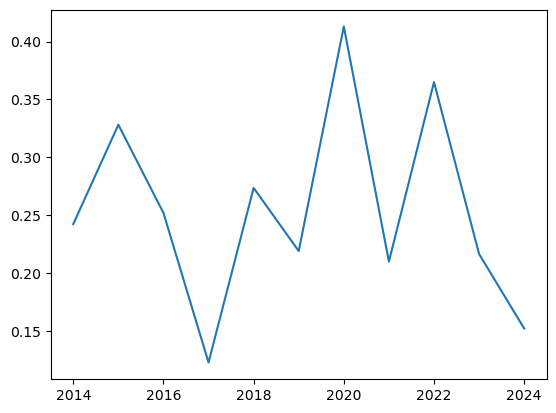

In [26]:
plt.plot(residcorrdict.keys(),residcorrdict.values())